# **1. Loading Dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset load karo
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/heart.csv")
print("Dataset has been successfully uploaded")


Dataset has been successfully uploaded


# **2. Check First and Last Rows**

In [ ]:
# To check first 5 rows:
df.head()

# To check last 5 rows:
df.tail()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
292,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,1
293,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
294,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,1
295,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,1
296,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


# **3. Check Info, Missing Values and Duplicates**

In [ ]:
# To check the data types:
df.info()

# To check missing values:
print(df.isnull().sum())

# To check the duplicate rows:
print("Duplicates:", df.duplicated().sum())

# To check summary:
print(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  target    297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 32.6 KB
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Duplicates

# **4. Clean the Data**

In [ ]:
# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Remove missing values
df = df.dropna()

# 3. Check target — 0 = no disease, 1 = disease
print(df["target"].value_counts())
print("Clean shape:", df.shape)


target
0    160
1    137
Name: count, dtype: int64
Clean shape: (297, 14)


# **5. EDA — Graphs**

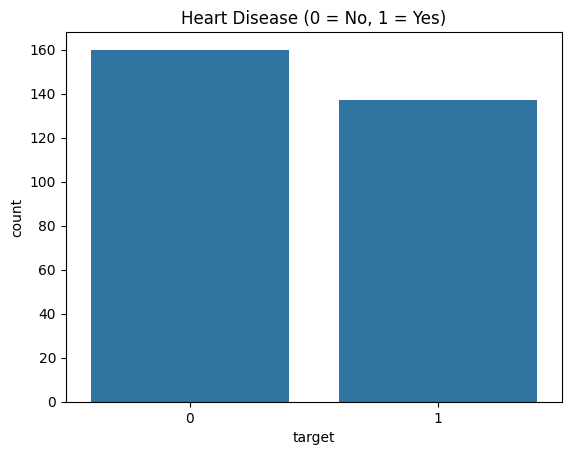

In [ ]:
#1. Target count plot
sns.countplot(x="target", data=df)
plt.title("Heart Disease (0 = No, 1 = Yes)")
plt.show()




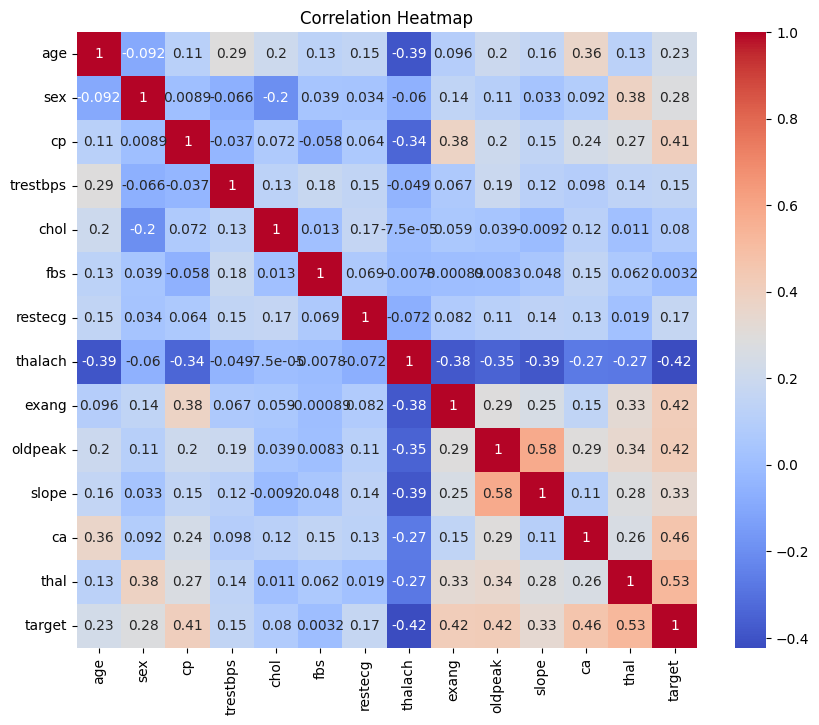

In [ ]:
#2. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


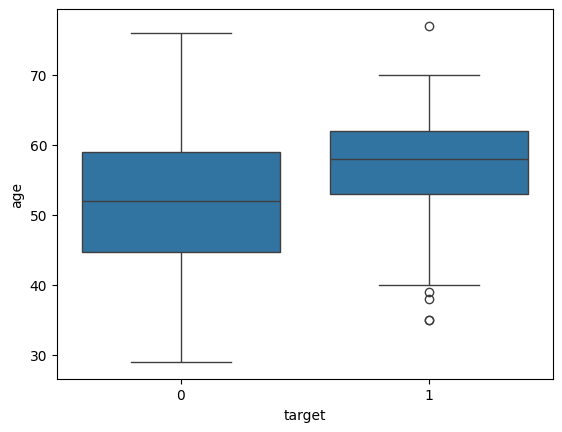

In [ ]:
#3. Age vs disease
sns.boxplot(x="target", y="age", data=df)
plt.show()


# **6. Prepare and Split the Data**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define input features (X) and target variable (y)
X = df.drop("target", axis=1)
y = df["target"]

# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# **7. Train the Models**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Initialize and train the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained!")


Logistic Regression trained!
Random Forest trained!
KNN trained!
SVM trained!


# **8. Evaluate the Models**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Recall:", round(recall_score(y_test, y_pred), 3))
    print("F1:", round(f1_score(y_test, y_pred), 3))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
    print(classification_report(y_test, y_pred))
    print("---")


Logistic Regression
Accuracy: 0.833
Recall: 0.786
F1: 0.815
ROC-AUC: 0.95
              precision    recall  f1-score   support

           0       0.82      0.88      0.85        32
           1       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

---
Random Forest
Accuracy: 0.867
Recall: 0.821
F1: 0.852
ROC-AUC: 0.941
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        32
           1       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60

---
KNN
Accuracy: 0.883
Recall: 0.821
F1: 0.868
ROC-AUC: 0.949
              precision    recall  f1-score   support

           0       0.86      0.94      0.90        32
           1       0.92    

# **9. Save the Best Model and Predict a New Patient**

In [ ]:
import joblib

# Best model save karo (Random Forest usually best hota hai)
best_model = models["Random Forest"]
joblib.dump(best_model, "heart_model.joblib")
joblib.dump(scaler, "scaler.joblib")
print("Model saved!")

# Predict a new patient — Test Patient 2 (High risk)
new_patient = pd.DataFrame([{
    "age": 67, "sex": 1, "cp": 4, "trestbps": 160, "chol": 286,
    "fbs": 0, "restecg": 2, "thalach": 108, "exang": 1,
    "oldpeak": 1.5, "slope": 2, "ca": 3, "thal": 3
}])

new_patient_scaled = scaler.transform(new_patient)
prediction = best_model.predict(new_patient_scaled)
risk = best_model.predict_proba(new_patient_scaled)[0][1]
print("Prediction:", prediction[0], "| Risk:", round(risk * 100, 1), "%")


Model saved!
Prediction: 1 | Risk: 88.0 %


In [ ]:
from google.colab import files
files.download("heart_model.joblib")
files.download("scaler.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>